>Implementar una función que calcule las componentes principales de un conjunto de datos a partir de su descomposici ́on en valores singulares (SVD). Para el calculo de las matrices de valores singulares pueden usar las bibliotecas y módulos ya conocidos

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from numpy import ndarray

df = pd.read_csv('./europe.csv', delimiter=',')
df.head()

,Country,Area,GDP,Inflation,Life.expect,Military,Pop.growth,Unemployment
0,Austria,83871,41600,3.5,79.91,0.80,0.03,4.2
1,Belgium,30528,37800,3.5,79.65,1.30,0.06,7.2
2,Bulgaria,110879,13800,4.2,73.84,2.60,-0.80,9.6
3,Croatia,56594,18000,2.3,75.99,2.39,-0.09,17.7
4,Czech Republic,78867,27100,1.9,77.38,1.15,-0.13,8.5


Voy a escalar el dataframe por comodidad. Podría no hacerlo y ver qué pasa

In [23]:
id = 'Country'
features = list(set(df.columns) - {id})
X = df[features].to_numpy()
std_scale = StandardScaler()
std_scale.fit(X)
X_scaled = std_scale.transform(X)

algoritmo PCA:
* centrar X
* Hacer SVD
* Calcular varianza por componente  y varianza total
* Calcular proporción de varianza explicada por componente
* Truncar matrices
* Proyectar X centrado sobre matrices calculadas
* Devolver $X_{proyectado}$ en $q$ componentes, $V_q^t$ (matriz de $q$ componentes principales), array con cantidad de varianza explicada por componente

In [24]:
def pca_svd(X:ndarray, n_componentes:int|None=None):
    X_bar = np.mean(X, axis=0)
    X_centrado = X - X_bar
    N = X.shape[0]
    
    #obs: d es un array
    U, d, Vt = np.linalg.svd(X_centrado, full_matrices=False)

    #varianza explicada
    sigma_cuad = (d ** 2) / (N - 1)
    var_total = np.sum(sigma_cuad)
    varianza_explicada_ratio = sigma_cuad / var_total

    if n_componentes is None:
        n_componentes = X.shape[1]
    #truncar a las primeras q dimensiones
    U_q = U[:, :n_componentes]
    D_q = np.diag(d[:n_componentes])
    Vt_q = Vt[:n_componentes, :]
    
    #calcular los lambda_ij = U_q * D_q
    X_proyectado = np.dot(U_q, D_q)  
    #se podría calcular de la misma forma X_proyectado = X_centrado @ Vt_q.T

    return X_proyectado, Vt_q, varianza_explicada_ratio[:n_componentes]

X_proyectado, componentes, varianza_explicada = pca_svd(X_scaled)

Grafiquitos ↓

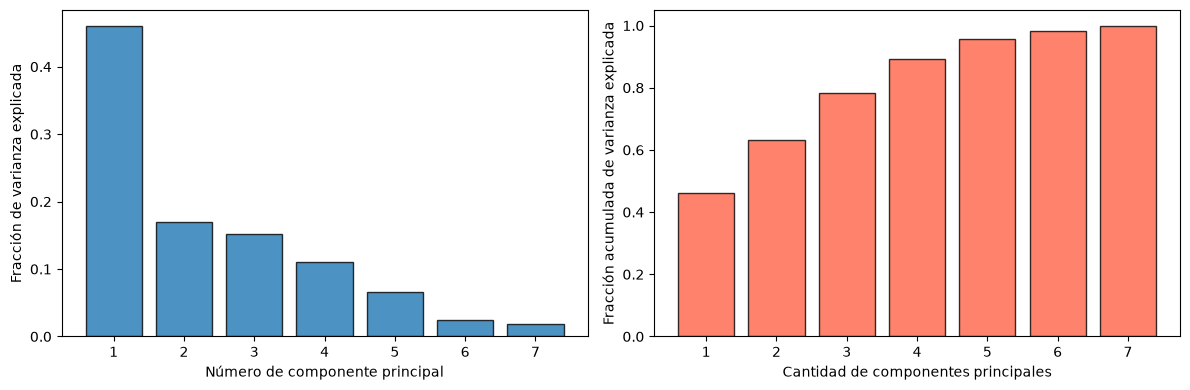

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Eje X común (número de componentes)
n_componentes = range(1, len(varianza_explicada) + 1)

# 1. Gráfico de varianza explicada individual
ax[0].bar(n_componentes, varianza_explicada, edgecolor='black', alpha=0.8)
ax[0].set_ylabel('Fracción de varianza explicada')
ax[0].set_xlabel('Número de componente principal')
ax[0].set_xticks(n_componentes) # Para asegurar que muestre cada número entero

# Varianza acumulada
varianza_acumulada = np.cumsum(varianza_explicada)

# 2. Gráfico de varianza acumulada
ax[1].bar(n_componentes, varianza_acumulada, color = 'tomato',edgecolor='black', alpha=0.8)
ax[1].set_ylabel('Fracción acumulada de varianza explicada')
ax[1].set_xlabel('Cantidad de componentes principales')
ax[1].set_xticks(n_componentes)

plt.tight_layout()
plt.show()

Composición de las componentes en función de las features originales

In [26]:
componentes_df = pd.DataFrame(
    [[round(float(a), 3) for a in componentes[i]] for i in range(len(componentes))],
    columns=features,
    index=[f'Comp. Principal {i}'for i in range(1, len(componentes) + 1)]
)
componentes_df

,Pop.growth,Area,Unemployment,Life.expect,Military,GDP,Inflation
Comp. Principal 1,0.476,-0.125,-0.272,0.483,-0.188,0.501,-0.407
Comp. Principal 2,-0.083,0.173,-0.553,-0.265,-0.658,0.130,0.370
Comp. Principal 3,-0.164,-0.898,-0.001,-0.246,-0.244,-0.084,-0.198
Comp. Principal 4,0.392,0.045,0.702,0.027,-0.562,-0.084,0.165
Comp. Principal 5,0.348,-0.324,0.010,-0.102,0.368,0.391,0.690
Comp. Principal 6,0.121,-0.190,-0.260,0.606,-0.036,-0.639,0.324
Comp. Principal 7,-0.671,-0.067,0.245,0.507,-0.137,0.397,0.227


Proyeccion de features en el espacio de componentes principales

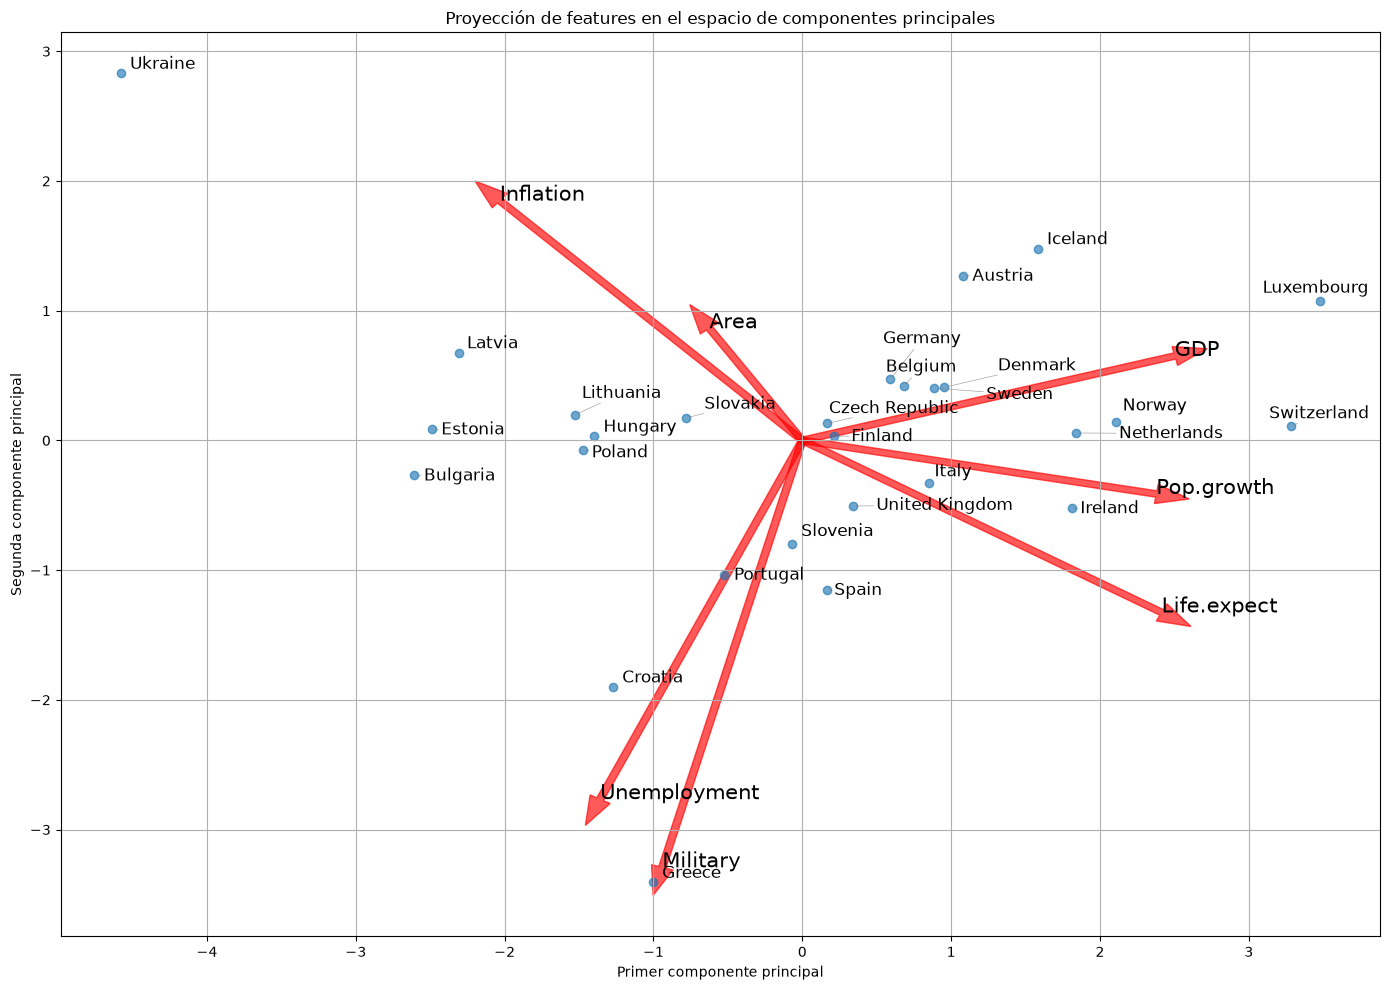

In [27]:
from adjustText import adjust_text
fig, ax = plt.subplots(figsize=(14, 10))
ax.grid(True)
ax.set_title('Proyección de features en el espacio de componentes principales')
texts = []

escala = 5
for i in range(len(features)):
    ax.arrow(0, 0, escala * componentes[0][i], escala * componentes[1][i], 
             width=0.05, color='r', alpha=0.65)
    ax.text(escala * componentes[0][i], escala * componentes[1][i], 
            s=features[i], fontdict={'color': 'k', 'size': 15})
for i, row in df.iterrows():
    pais = row[id]
    t = ax.text(X_proyectado[i, 0], X_proyectado[i, 1], pais, fontsize=12)
    texts.append(t)

ax.scatter(X_proyectado[:, 0], X_proyectado[:, 1], alpha=0.65)


adjust_text(texts, ax=ax, 
            arrowprops=dict(arrowstyle='->', color='gray', lw=0.5, alpha=0.7))

ax.set_xlabel('Primer componente principal')
ax.set_ylabel('Segunda componente principal')
plt.tight_layout()
plt.show()

Repito análisis con la implementación de sklearn

In [28]:
from sklearn.decomposition import PCA
pca = PCA(n_components=None)
pca.fit(X_scaled)
X_proyectado_sklearn = pca.transform(X_scaled)
varianza_explicada_sklearn = pca.explained_variance_ratio_
componentes_sklearn = pca.components_

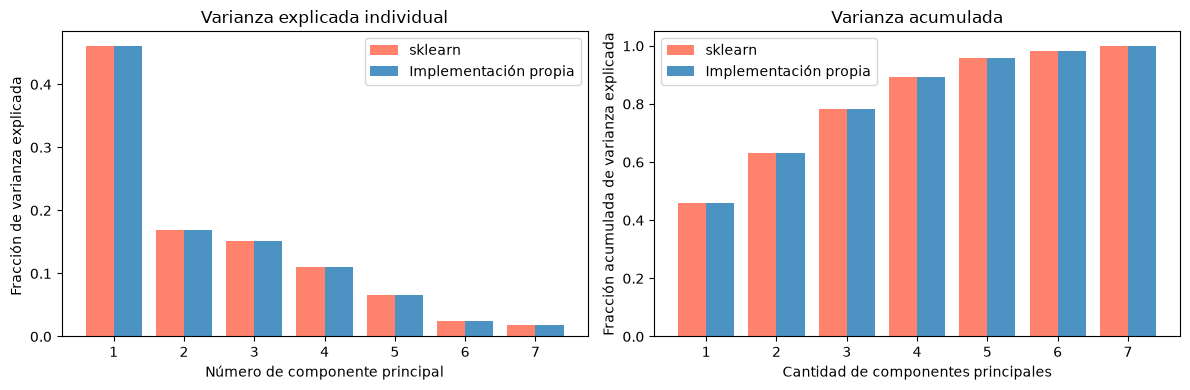

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Eje X común (número de componentes)
n_componentes = np.arange(1, len(varianza_explicada_sklearn) + 1)
ancho = 0.4  # ancho de cada barra: sklearn a la izquierda, implementación propia a la derecha

# 1. Gráfico de varianza explicada individual
ax[0].bar(n_componentes - ancho / 2, varianza_explicada_sklearn, width=ancho, color = 'tomato', alpha=0.8, label='sklearn')
ax[0].bar(n_componentes + ancho / 2, varianza_explicada, width=ancho, alpha=0.8, label='Implementación propia')
ax[0].set_ylabel('Fracción de varianza explicada ')
ax[0].set_xlabel('Número de componente principal')
ax[0].set_xticks(n_componentes) # Para asegurar que muestre cada número entero
ax[0].set_title('Varianza explicada individual')
ax[0].legend()
# Varianza acumulada
varianza_acumulada_sklearn = np.cumsum(varianza_explicada_sklearn)

# 2. Gráfico de varianza acumulada
ax[1].bar(n_componentes - ancho / 2, varianza_acumulada_sklearn, width=ancho, color = 'tomato', alpha=0.8, label='sklearn')
ax[1].bar(n_componentes + ancho / 2, varianza_acumulada, width=ancho, alpha=0.8, label='Implementación propia')
ax[1].legend()
ax[1].set_ylabel('Fracción acumulada de varianza explicada')
ax[1].set_xlabel('Cantidad de componentes principales')
ax[1].set_xticks(n_componentes)
ax[1].set_title('Varianza acumulada')
plt.tight_layout()
plt.show()

In [30]:

componentes_df_sklearn = pd.DataFrame(
    [[round(float(a), 3) for a in componentes_sklearn[i]] for i in range(len(componentes_sklearn))],
     
    columns=features,
    index=[f'Comp. Principal {i}' for i in range(1, len(componentes_sklearn) + 1)]
)
print('Comparación de componentes principales')
print('-----------------------------------')
for i, row in componentes_df.iterrows():
    print(f'{i}:\n{componentes_df_sklearn.loc[i].values} (sklearn) \n{componentes_df.loc[i].values} (implementación propia)\n')


Comparación de componentes principales
-----------------------------------
Comp. Principal 1:
[ 0.476 -0.125 -0.272  0.483 -0.188  0.501 -0.407] (sklearn) 
[ 0.476 -0.125 -0.272  0.483 -0.188  0.501 -0.407] (implementación propia)

Comp. Principal 2:
[ 0.083 -0.173  0.553  0.265  0.658 -0.13  -0.37 ] (sklearn) 
[-0.083  0.173 -0.553 -0.265 -0.658  0.13   0.37 ] (implementación propia)

Comp. Principal 3:
[0.164 0.898 0.001 0.246 0.244 0.084 0.198] (sklearn) 
[-0.164 -0.898 -0.001 -0.246 -0.244 -0.084 -0.198] (implementación propia)

Comp. Principal 4:
[ 0.392  0.045  0.702  0.027 -0.562 -0.084  0.165] (sklearn) 
[ 0.392  0.045  0.702  0.027 -0.562 -0.084  0.165] (implementación propia)

Comp. Principal 5:
[ 0.348 -0.324  0.01  -0.102  0.368  0.391  0.69 ] (sklearn) 
[ 0.348 -0.324  0.01  -0.102  0.368  0.391  0.69 ] (implementación propia)

Comp. Principal 6:
[-0.121  0.19   0.26  -0.606  0.036  0.639 -0.324] (sklearn) 
[ 0.121 -0.19  -0.26   0.606 -0.036 -0.639  0.324] (implementación

SKLearn invierte el sentido de las componentes 1, 4, 6 y 7 respecto de las de la implementación propia. Esto se puede observar en la inversión horizontal del gráfico siguiente


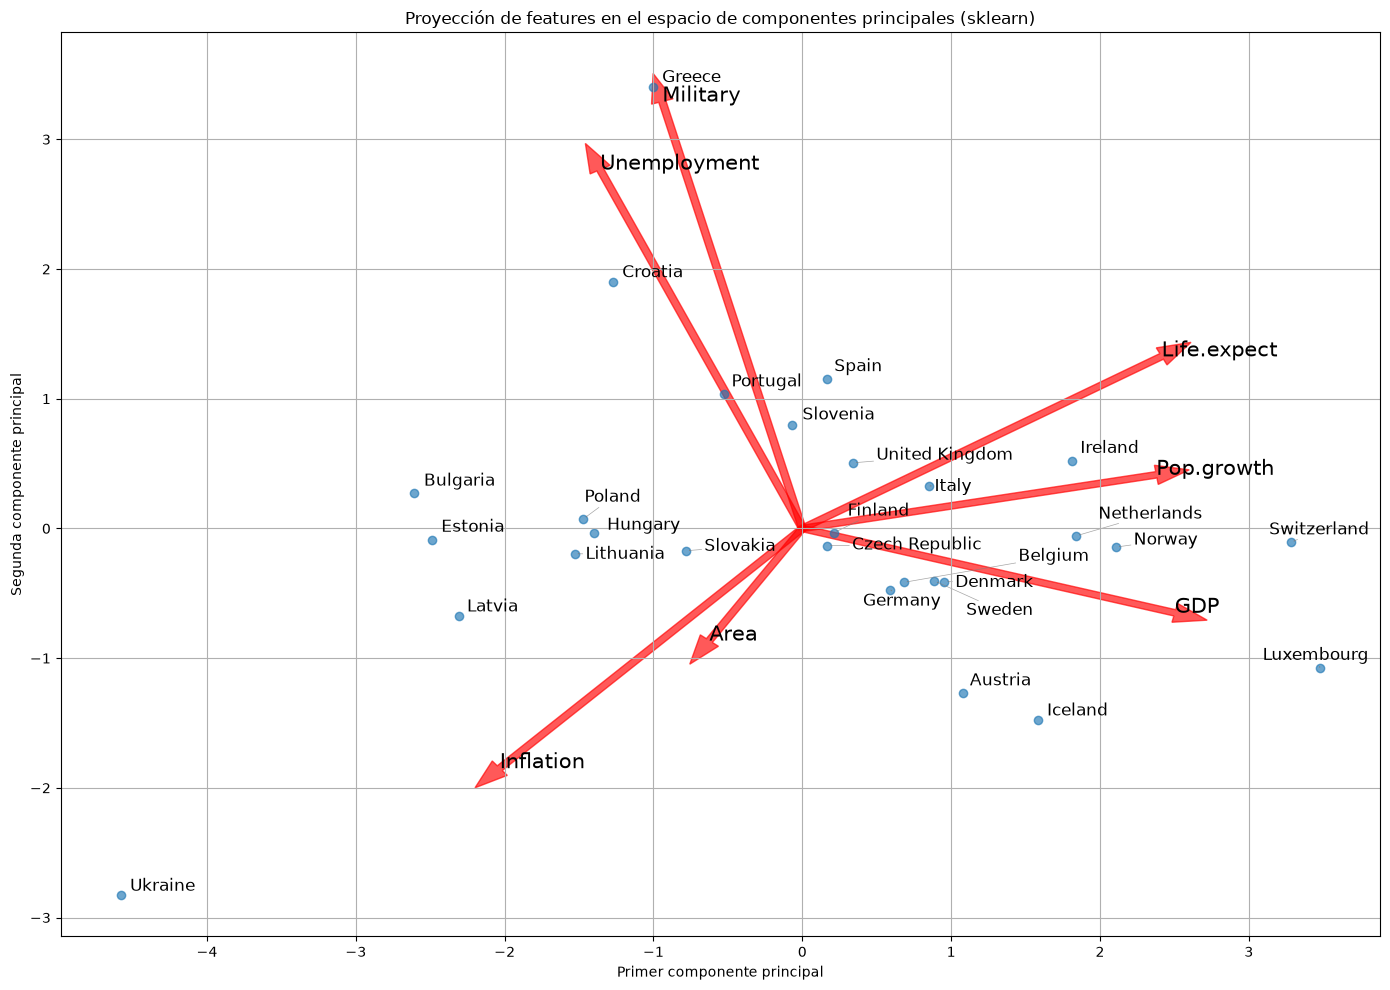

In [31]:
fig, ax = plt.subplots(figsize=(14, 10))
ax.grid(True)
ax.set_title('Proyección de features en el espacio de componentes principales (sklearn)')
texts = []

escala = 5
for i in range(len(features)):
    ax.arrow(0, 0, escala * componentes_sklearn[0][i], escala * componentes_sklearn[1][i], 
             width=0.05, color='r', alpha=0.65)
    ax.text(escala * componentes_sklearn[0][i], escala * componentes_sklearn[1][i], 
            s=features[i], fontdict={'color': 'k', 'size': 15})
for i, row in df.iterrows():
    pais = row[id]
    t = ax.text(X_proyectado_sklearn[i, 0], X_proyectado_sklearn[i, 1], pais, fontsize=12)
    texts.append(t)

ax.scatter(X_proyectado_sklearn[:, 0], X_proyectado_sklearn[:, 1], alpha=0.65)


adjust_text(texts, ax=ax, 
            arrowprops=dict(arrowstyle='->', color='gray', lw=0.5, alpha=0.7))

ax.set_xlabel('Primer componente principal')
ax.set_ylabel('Segunda componente principal')
plt.tight_layout()
plt.show()

Agregamos cuatro filas de datos al conjunto original: Argentina del 2012, del 2024, Brasil del 2012 y del 2024. Las iremos introduciendo de a una al análisis para observar cómo cada nuevo dato cambia los resultados.

El primer dato agregado corresponde a Argentina del 2012, año que se corresponde con las mediciones de los datos originales

In [32]:
df_expandido = pd.read_csv('./dataset_expandido.csv', delimiter=',')
df_expandido.tail()

X_expandido = df_expandido[features].to_numpy()
std_scaler_2 = StandardScaler()
std_scaler_2.fit(X_expandido)
X_scaled_expandido = std_scaler_2.transform(X_expandido)
X_proyectado_expandido, componentes_expandido, varianza_explicada_expandido = pca_svd(X_scaled_expandido)

Proyección de las features en el espacio de componentes


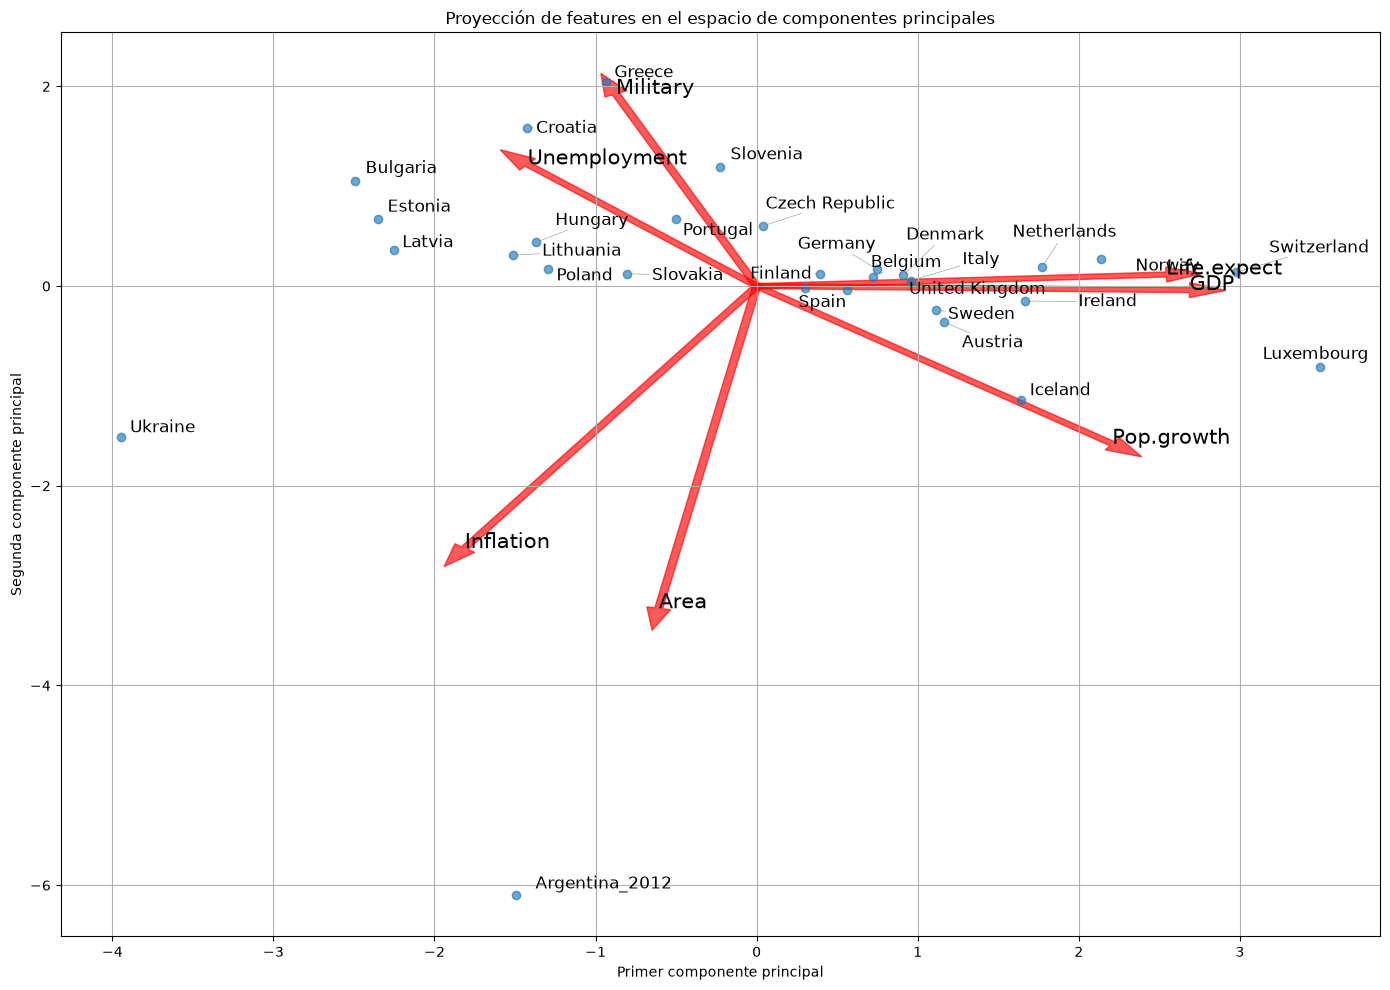

In [33]:

fig, ax = plt.subplots(figsize=(14, 10))
ax.grid(True)
ax.set_title('Proyección de features en el espacio de componentes principales')
texts = []

escala = 5
for i in range(len(features)):
    ax.arrow(0, 0, escala * componentes_expandido[0][i], escala * componentes_expandido[1][i], 
             width=0.05, color='r', alpha=0.65)
    ax.text(escala * componentes_expandido[0][i], escala * componentes_expandido[1][i], 
            s=features[i], fontdict={'color': 'k', 'size': 15})
for i, row in df_expandido.iterrows():
    pais = row[id]
    t = ax.text(X_proyectado_expandido[i, 0], X_proyectado_expandido[i, 1], pais, fontsize=12)
    texts.append(t)

ax.scatter(X_proyectado_expandido[:, 0], X_proyectado_expandido[:, 1], alpha=0.65)


adjust_text(texts, ax=ax, 
            arrowprops=dict(arrowstyle='->', color='gray', lw=0.5, alpha=0.7))

ax.set_xlabel('Primer componente principal')
ax.set_ylabel('Segunda componente principal')
plt.tight_layout()
plt.show()

Proyectamos los países nuevos sobre las componentes principales calculadas con los datos originales, sin recalcular el PCA. Para eso los escalamos con el mismo `StandardScaler` ajustado sobre `europe.csv` y usamos `pca.transform` (sklearn)

In [34]:
df_mas_expandido = pd.read_csv('./dataset_mas_expandido.csv', delimiter=',')
df_nuevos = df_mas_expandido[~df_mas_expandido[id].isin(df[id])].reset_index(drop=True)

X_nuevos_scaled = std_scale.transform(df_nuevos[features].to_numpy())
X_nuevos_proyectado = pca.transform(X_nuevos_scaled)
df_nuevos

,Country,Area,GDP,Inflation,Life.expect,Military,Pop.growth,Unemployment
0,Argentina_2012,2780400,17400,9.8,77.14,0.8,0.98,7.2
1,Argentina_2024,2780400,22100,140.0,78.00,0.4,0.81,7.6
2,Brazil_2012,8515770,11900,5.4,72.79,1.5,0.88,6.0
3,Brazil_2024,8515770,18100,4.0,76.00,1.1,0.62,7.5


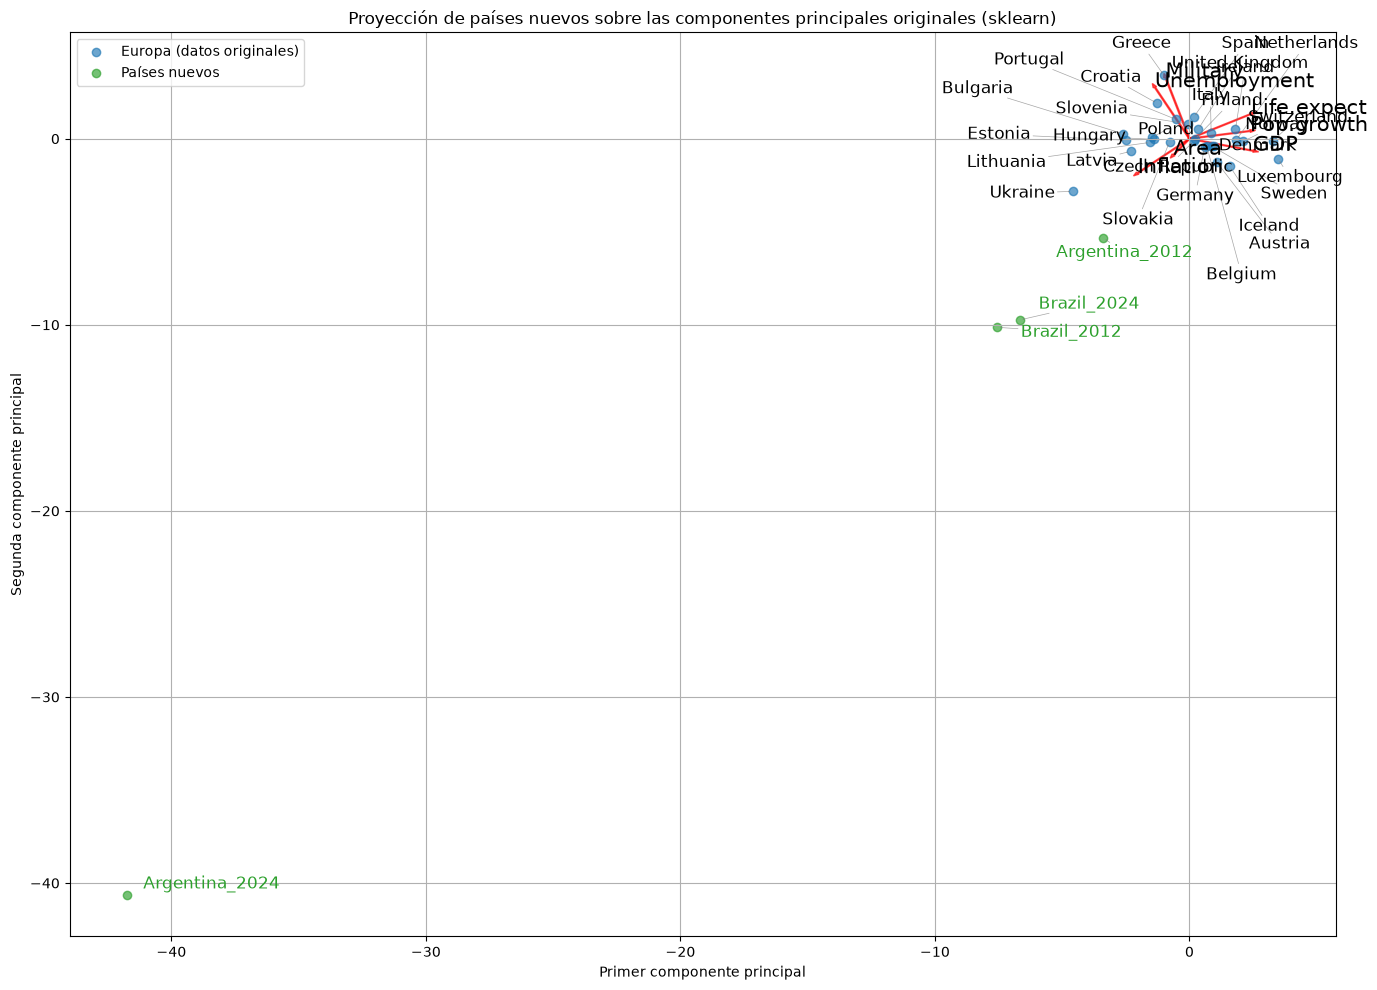

In [35]:
fig, ax = plt.subplots(figsize=(14, 10))
ax.grid(True)
ax.set_title('Proyección de países nuevos sobre las componentes principales originales (sklearn)')
texts = []

escala = 5
for i in range(len(features)):
    ax.arrow(0, 0, escala * componentes_sklearn[0][i], escala * componentes_sklearn[1][i], 
             width=0.05, color='r', alpha=0.65)
    ax.text(escala * componentes_sklearn[0][i], escala * componentes_sklearn[1][i], 
            s=features[i], fontdict={'color': 'k', 'size': 15})
for i, row in df.iterrows():
    pais = row[id]
    t = ax.text(X_proyectado_sklearn[i, 0], X_proyectado_sklearn[i, 1], pais, fontsize=12)
    texts.append(t)
for i, row in df_nuevos.iterrows():
    pais = row[id]
    t = ax.text(X_nuevos_proyectado[i, 0], X_nuevos_proyectado[i, 1], pais, fontsize=12, color='tab:green')
    texts.append(t)

ax.scatter(X_proyectado_sklearn[:, 0], X_proyectado_sklearn[:, 1], alpha=0.65, label='Europa (datos originales)')
ax.scatter(X_nuevos_proyectado[:, 0], X_nuevos_proyectado[:, 1], alpha=0.65, color='tab:green', label='Países nuevos')
ax.legend()

adjust_text(texts, ax=ax, 
            arrowprops=dict(arrowstyle='->', color='gray', lw=0.5, alpha=0.7))

ax.set_xlabel('Primer componente principal')
ax.set_ylabel('Segunda componente principal')
plt.tight_layout()
plt.show()

Recalculamos el PCA incluyendo los cuatro países nuevos (el escalado también se ajusta sobre el conjunto completo)

In [36]:
X_todos = df_mas_expandido[features].to_numpy()
std_scaler_todos = StandardScaler()
std_scaler_todos.fit(X_todos)
X_scaled_todos = std_scaler_todos.transform(X_todos)

pca_todos = PCA(n_components=None)
pca_todos.fit(X_scaled_todos)
X_proyectado_todos = pca_todos.transform(X_scaled_todos)
componentes_todos = pca_todos.components_
es_nuevo_todos = ~df_mas_expandido[id].isin(df[id]).to_numpy()

Comparación lado a lado: países nuevos proyectados sobre el PCA original (izquierda) vs. PCA recalculado con todos los países (derecha)

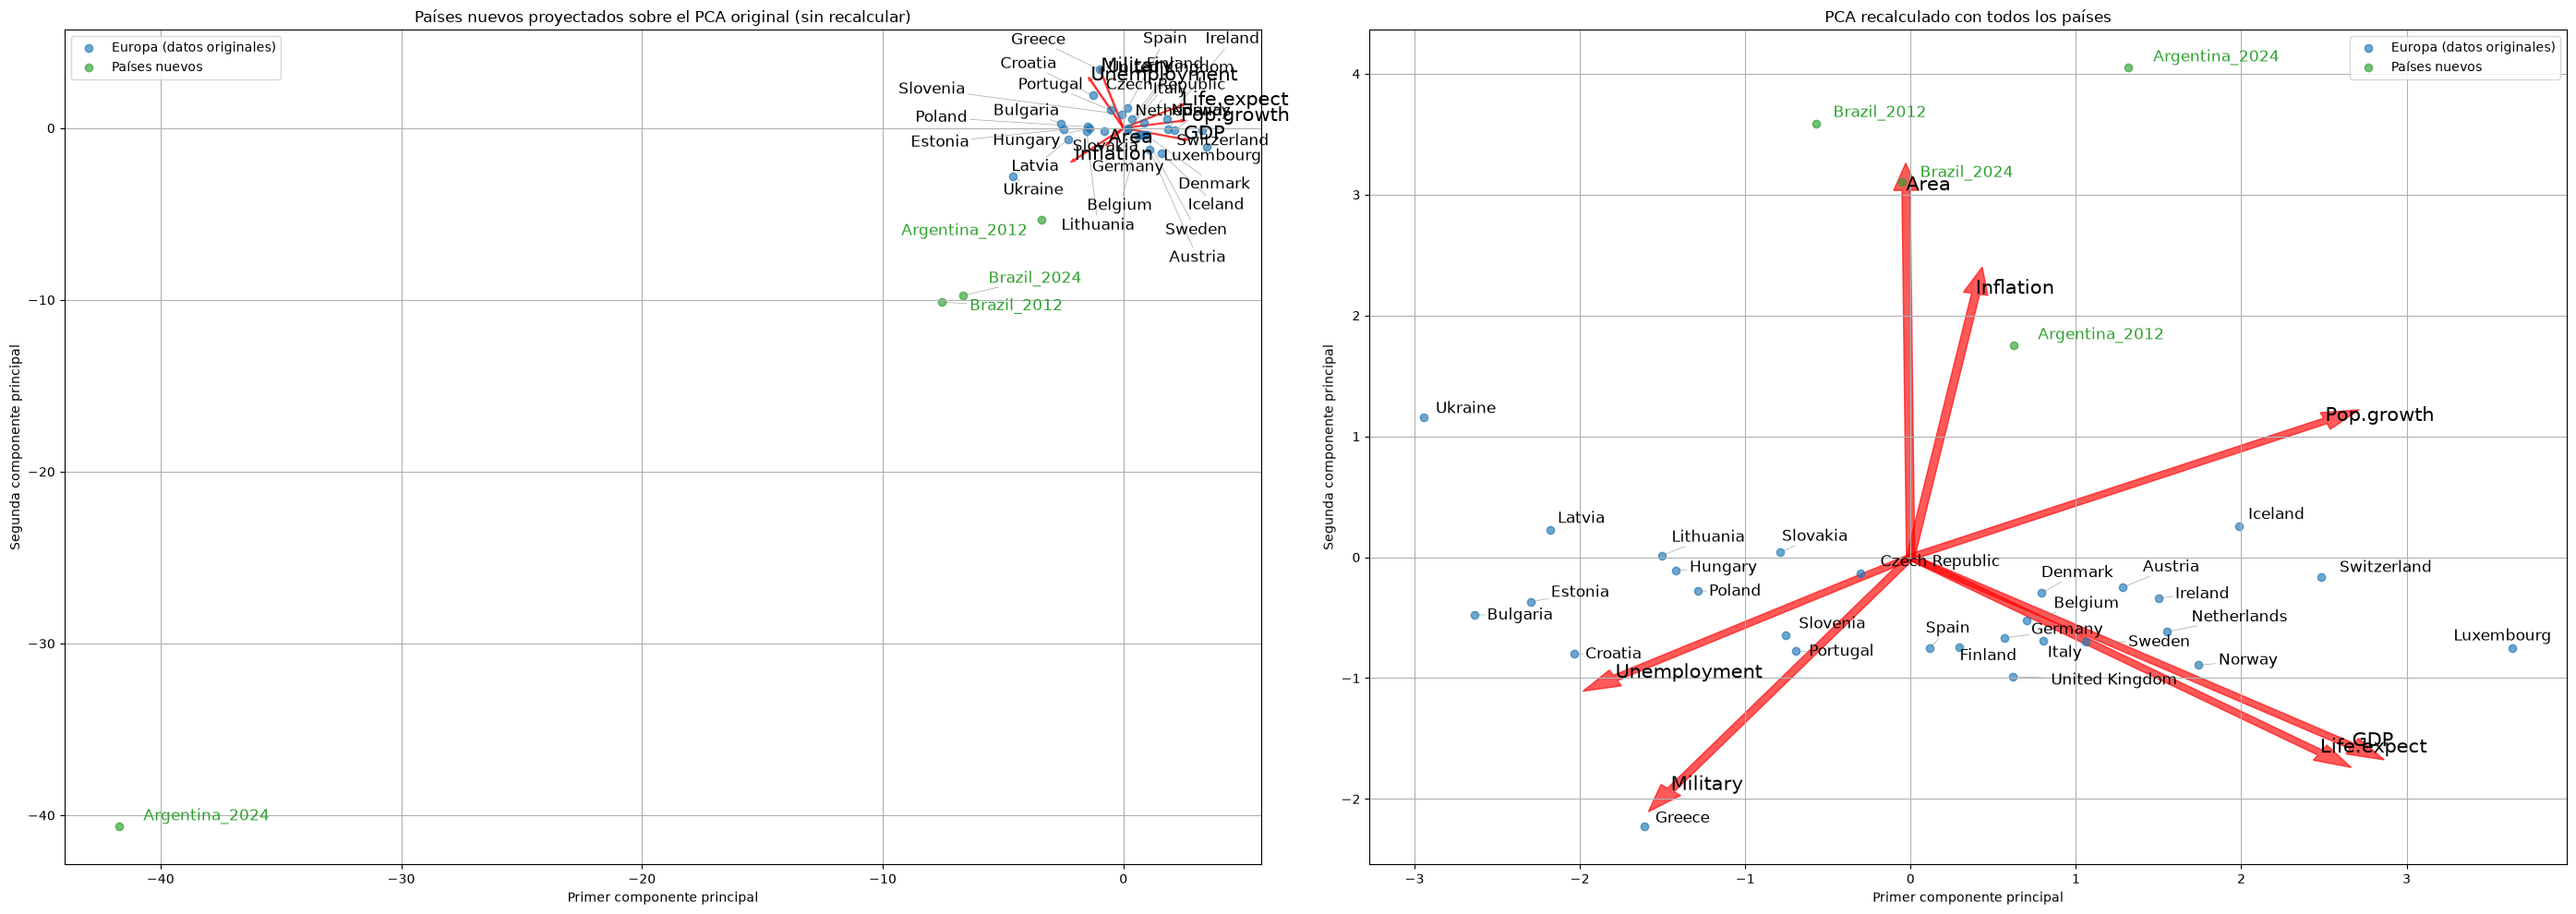

In [37]:
def plot_biplot(ax, componentes, X_proy, paises, es_nuevo, titulo, escala=5):
    ax.grid(True)
    ax.set_title(titulo)
    texts = []
    for i in range(len(features)):
        ax.arrow(0, 0, escala * componentes[0][i], escala * componentes[1][i], 
                 width=0.05, color='r', alpha=0.65)
        ax.text(escala * componentes[0][i], escala * componentes[1][i], 
                s=features[i], fontdict={'color': 'k', 'size': 15})
    for i, pais in enumerate(paises):
        color = 'tab:green' if es_nuevo[i] else 'k'
        texts.append(ax.text(X_proy[i, 0], X_proy[i, 1], pais, fontsize=12, color=color))

    ax.scatter(X_proy[~es_nuevo, 0], X_proy[~es_nuevo, 1], alpha=0.65, label='Europa (datos originales)')
    ax.scatter(X_proy[es_nuevo, 0], X_proy[es_nuevo, 1], alpha=0.65, color='tab:green', label='Países nuevos')
    ax.legend()
    adjust_text(texts, ax=ax, 
                arrowprops=dict(arrowstyle='->', color='gray', lw=0.5, alpha=0.7))
    ax.set_xlabel('Primer componente principal')
    ax.set_ylabel('Segunda componente principal')

X_proy_sin_recalcular = np.vstack([X_proyectado_sklearn, X_nuevos_proyectado])
paises_sin_recalcular = list(df[id]) + list(df_nuevos[id])
es_nuevo_sin_recalcular = np.array([False] * len(df) + [True] * len(df_nuevos))

fig, ax = plt.subplots(1, 2, figsize=(28, 10))
plot_biplot(ax[0], componentes_sklearn, X_proy_sin_recalcular, paises_sin_recalcular, es_nuevo_sin_recalcular,
            'Países nuevos proyectados sobre el PCA original (sin recalcular)')
plot_biplot(ax[1], componentes_todos, X_proyectado_todos, df_mas_expandido[id], es_nuevo_todos,
            'PCA recalculado con todos los países')
plt.tight_layout()
plt.show()

SPLOM de las variables originales (todos los países), con histogramas en la diagonal

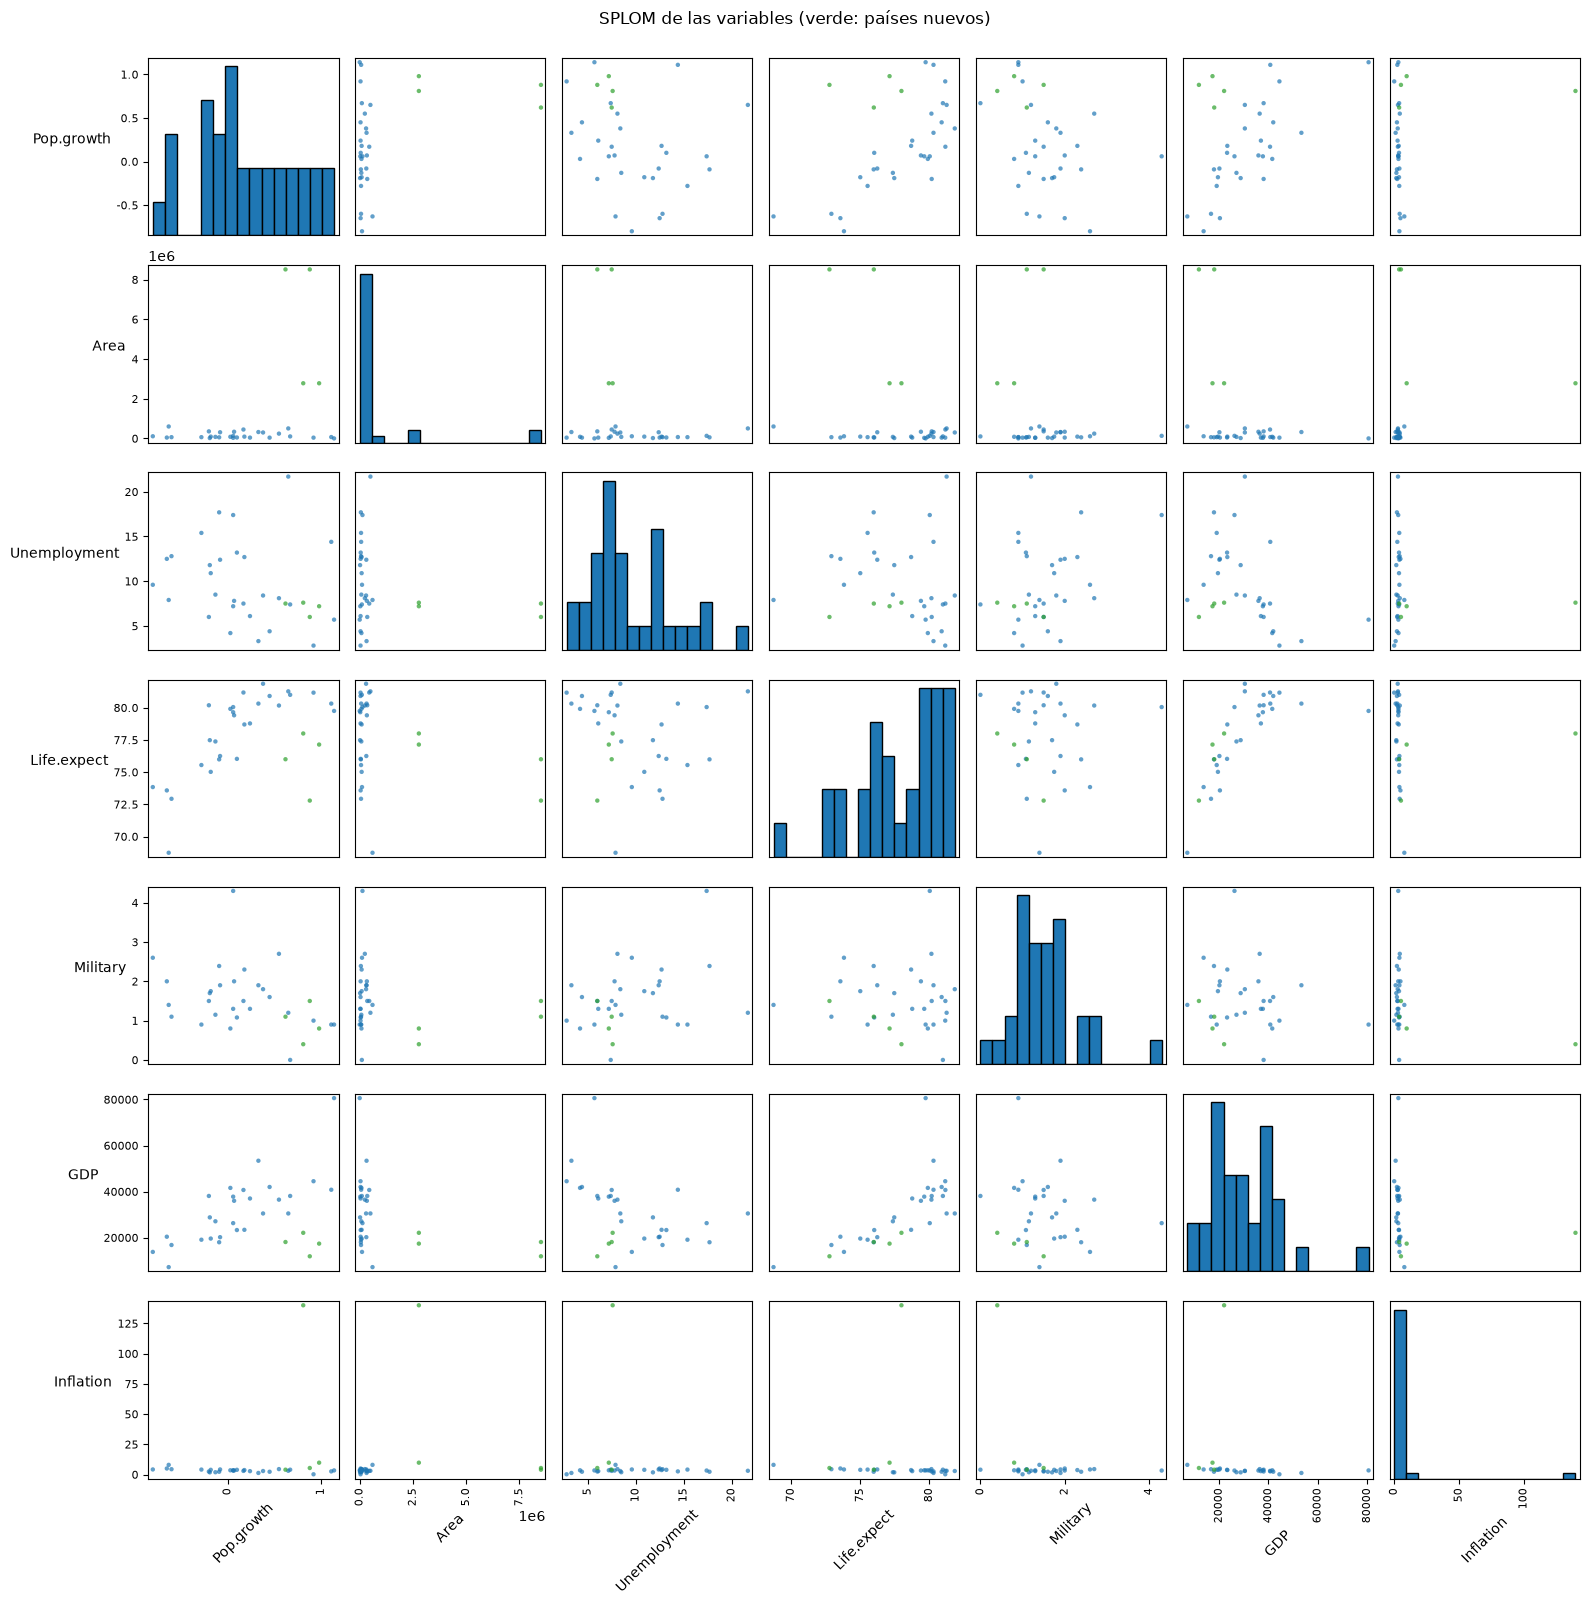

In [38]:
colores = np.where(es_nuevo_todos, 'tab:green', 'tab:blue')
axes = pd.plotting.scatter_matrix(df_mas_expandido[features], figsize=(16, 16), diagonal='hist',
                                  c=colores, alpha=0.7, s=40, hist_kwds={'bins': 15, 'edgecolor': 'black'})
for a in axes.flatten():
    a.xaxis.label.set_rotation(45)
    a.yaxis.label.set_rotation(0)
    a.yaxis.label.set_ha('right')
plt.suptitle('SPLOM de las variables (verde: países nuevos)', y=1.0)
plt.tight_layout()
plt.show()

Comparación: PCA con los datos estandarizados vs. sin estandarizar

Repito el mismo análisis pero pasándole a `pca_svd` la matriz `X` original (la función igual centra los datos, así que la única diferencia es la escala de cada variable).

In [39]:
X_proyectado_raw, componentes_raw, varianza_explicada_raw = pca_svd(X)

print(f'Features = {features}')
print(f'Varianza por feature (sin estandarizar) = {[f"{v:.3g}" for v in X.var(axis=0, ddof=1)]}')
print(f'Comp. Principal 1 = {[round(float(a), 3) for a in componentes_raw[0]]}')
print(f'Comp. Principal 2 = {[round(float(a), 3) for a in componentes_raw[1]]}')
print(f'Varianza explicada (estandarizado)    = {np.round(varianza_explicada[:3], 3)}')
print(f'Varianza explicada (sin estandarizar) = {np.round(varianza_explicada_raw[:3], 3)}')

Features = ['Pop.growth', 'Area', 'Unemployment', 'Life.expect', 'Military', 'GDP', 'Inflation']
Varianza por feature (sin estandarizar) = ['0.252', '2.74e+10', '21.9', '10.2', '0.642', '2.1e+08', '1.96']
Comp. Principal 1 = [-0.0, 1.0, 0.0, -0.0, 0.0, -0.012, 0.0]
Comp. Principal 2 = [0.0, 0.012, -0.0, 0.0, -0.0, 1.0, -0.0]
Varianza explicada (estandarizado)    = [0.461 0.17  0.152]
Varianza explicada (sin estandarizar) = [0.993 0.007 0.   ]


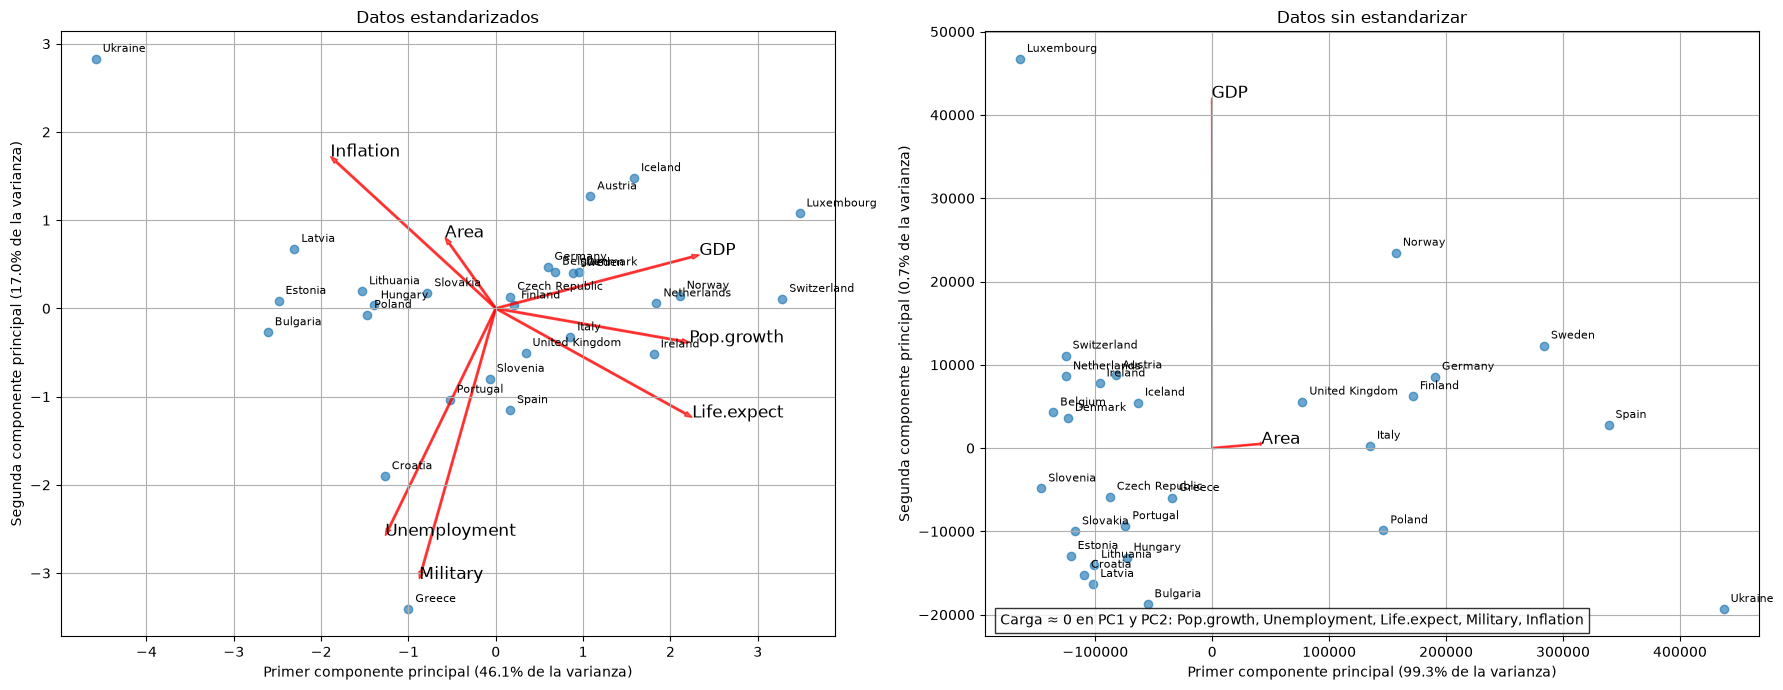

In [40]:
def biplot(ax, X_proy, comps, var_exp, titulo):
    ax.grid()
    ax.set_title(titulo)
    ax.scatter(X_proy[:, 0], X_proy[:, 1], alpha=0.65)
    for i, row in df.iterrows():
        ax.annotate(row[id], (X_proy[i, 0], X_proy[i, 1]), xytext=(5, 5), textcoords='offset points', fontsize=8)

    # Escala de las flechas relativa al rango de los datos proyectados, para que
    # entren en el gráfico en ambos casos (las escalas son muy distintas)
    escala = 0.9 * min(np.abs(X_proy[:, k]).max() / np.abs(comps[k]).max() for k in range(2))
    despreciables = []
    for i in range(len(features)):
        # Las features con carga casi nula en ambas componentes no se dibujan (quedarían todas encimadas en el origen)
        if np.hypot(comps[0][i], comps[1][i]) < 0.05:
            despreciables.append(features[i])
            continue
        ax.arrow(0, 0, escala * comps[0][i], escala * comps[1][i], color='r', alpha=0.65,
                 width=0.004 * escala, length_includes_head=True)
        ax.text(escala * comps[0][i], escala * comps[1][i], s=features[i], fontdict={'color': 'k', 'size': 12})
    if despreciables:
        ax.text(0.02, 0.02, 'Carga ≈ 0 en PC1 y PC2: ' + ', '.join(despreciables), transform=ax.transAxes,
                fontsize=10, bbox={'facecolor': 'white', 'alpha': 0.8})
    ax.set_xlabel(f'Primer componente principal ({var_exp[0]:.1%} de la varianza)')
    ax.set_ylabel(f'Segunda componente principal ({var_exp[1]:.1%} de la varianza)')

fig, ax = plt.subplots(1, 2, figsize=(18, 7))
biplot(ax[0], X_proyectado, componentes, varianza_explicada, 'Datos estandarizados')
biplot(ax[1], X_proyectado_raw, componentes_raw, varianza_explicada_raw, 'Datos sin estandarizar')
plt.tight_layout()
plt.show()

Sin estandarizar, PCA queda dominado por las variables con mayor varianza en sus unidades originales: `Area` (varianza ~$10^{10}$, en km²) y `GDP` (~$10^{8}$). La PC1 es prácticamente `Area` sola (99.3% de la varianza) y la PC2 es `GDP`; el resto de las features tiene carga ≈ 0, así que el gráfico solo ordena a los países por superficie y PBI per cápita.

Al estandarizar, todas las variables pesan lo mismo y las componentes reflejan la estructura de correlación: la PC1 opone `GDP`, `Life.expect` y `Pop.growth` a `Inflation` y `Unemployment`, y la varianza queda más repartida (46%, 17%, 15%). Como las features están en unidades distintas, tiene sentido estandarizar.